# Chương 4 — Mạng MLP

Các đoạn mã ngắn in trong phần lý thuyết của Chương 4 (mục 4.4 và 4.5), theo đúng thứ tự xuất hiện trong sách.


# Mục 4.4

##(1) Tải bộ dữ liệu AI4I 2020 về Colab

In [81]:
# Tai bo du lieu AI4I 2020 ve thu muc lam viec cua Colab (chay mot lan).
# Neu tai khong duoc, tai tay tep ai4i2020.csv tai
# https://archive.ics.uci.edu/dataset/601 roi tai len Colab.
import os, urllib.request, zipfile

URL = ("https://archive.ics.uci.edu/static/public/601/"
       "ai4i+2020+predictive+maintenance+dataset.zip")
if not os.path.exists("ai4i2020.csv"):
    urllib.request.urlretrieve(URL, "ai4i2020.zip")
    with zipfile.ZipFile("ai4i2020.zip") as z:
        z.extract("ai4i2020.csv")
print("Da co ai4i2020.csv:", os.path.getsize("ai4i2020.csv"), "byte")

Da co ai4i2020.csv: 522048 byte


## (2) Khai báo mạng bằng API Sequential

In [82]:
from tensorflow import keras
# Mang 9-64-32-10 cho bai toan chan doan o lan
# Mang 8-32-16-1
model = keras.Sequential([
    keras.layers.Input(shape=(8,)),
    keras.layers.Dense(32, activation="relu"),
    keras.layers.Dense(16, activation="relu"),
    # keras.layers.Dense(1) # output hồi quy
    keras.layers.Dense(1, activation="sigmoid") # output 2 trạng thái
    # keras.layers.Dense(10, activation="softmax"),  # output 10 trang thai
])

model.summary()

Model: "sequential_103"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_318 (Dense)               │ (None, 32)             │           288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_319 (Dense)               │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_320 (Dense)               │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 833 (3.25 KB)

 Trainable params: 833 (3.25 KB)

 Non-trainable params: 0 (0.00 B)

### (*) Khai báo mạng bằng API Functional

In [83]:
from tensorflow import keras

# Khai bao lai mang bang API Functional
dau_vao = keras.Input(shape=(8,))
x       = keras.layers.Dense(32, activation="relu")(dau_vao)
x       = keras.layers.Dense(16, activation="relu")(x)
dau_ra  = keras.layers.Dense(1, activation="sigmoid")(x)

model = keras.Model(inputs=dau_vao, outputs=dau_ra)
model.summary()

Model: "functional_137"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_107 (InputLayer)    │ (None, 8)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_321 (Dense)               │ (None, 32)             │           288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_322 (Dense)               │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_323 (Dense)               │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 833 (3.25 KB)

 Trainable params: 833 (3.25 KB)

 Non-trainable params: 0 (0.00 B)

## (3) Biên dịch mô hình: optimizer, loss, metrics

In [84]:
# model.compile(
    # optimizer: ten chuoi -> dung tham so mac dinh
    #            doi tuong -> tu dat toc do hoc
    # optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    # loss chon theo bai toan va cach ma hoa nhan:
    #   "mse", "mae"                      -> hoi quy
    #   "binary_crossentropy"             -> nhi phan, 1 no-ron
    #   "categorical_crossentropy"        -> da lop, nhan one-hot
    #   "sparse_categorical_crossentropy" -> da lop, nhan nguyen
    # loss="sparse_categorical_crossentropy",
    # metrics chi de theo doi, khong tham gia toi uu
    # metrics=["accuracy"],
#)

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

## (4) Huấn luyện mô hình:

### Chuẩn bị dữ liệu

In [85]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# 1. Chuan bi du lieu: 5 dai luong do + loai may (L/M/H) -> 8 cot
df = pd.read_csv("ai4i2020.csv")
DO = ["Air temperature [K]", "Process temperature [K]",
      "Rotational speed [rpm]", "Torque [Nm]", "Tool wear [min]"]
X = pd.concat([df[DO], pd.get_dummies(df["Type"], dtype=float)],
              axis=1).values
y = df["Machine failure"].values    # 0 binh thuong, 1 hong

# Chia 64 / 16 / 20 %, giu nguyen ti le mau hong o ca ba tap
X_tam, X_te, y_tam, y_te = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)
X_tr, X_val, y_tr, y_val = train_test_split(
    X_tam, y_tam, test_size=0.2, stratify=y_tam, random_state=42)

# Chuan hoa: tham so chi uoc luong tren tap huan luyen
chuan_hoa = StandardScaler().fit(X_tr)
X_tr, X_val, X_te = [chuan_hoa.transform(a)
                     for a in (X_tr, X_val, X_te)]
print(X_tr.shape, X_val.shape, X_te.shape)   # 6400/1600/2000

(6400, 8) (1600, 8) (2000, 8)


### Huấn luyện không dừng sớm

In [86]:
print("Đang huấn luyện mạng ...")
history = model.fit(
    X_tr, y_tr,
    validation_data=(X_val, y_val),  # hoac validation_split=0.2
    epochs=100,           # so luot duyet het tap huan luyen
    batch_size=128,      # so mau moi lo; 616 mau -> 5 lo/epoch
    shuffle=True,        # tron lai truoc moi epoch (mac dinh)
    verbose=0,           # 0 im lang, 1 thanh tien trinh,
                         # 2 moi epoch mot dong
    # class_weight={0: 1.0, 1: 5.0},   # khi lech lop
    #callbacks=[early_stop]             # dừng sớm
)

print("\nKết thúc huấn luyện!")
num_epochs = len(history.history['loss'])
print(f"Số epoch đã chạy: {num_epochs}")
print(f"Training Accuracy: {history.history['accuracy'][-1]:.3f}")
print(f"Training Loss: {history.history['loss'][-1]:.3f}")
print(f"Validation Accuracy: {history.history['val_accuracy'][-1]:.3f}")
print(f"Validation Loss: {history.history['val_loss'][-1]:.3f}")

Đang huấn luyện mạng ...

Kết thúc huấn luyện!
Số epoch đã chạy: 100
Training Accuracy: 0.984
Training Loss: 0.049
Validation Accuracy: 0.979
Validation Loss: 0.070


### Callback dừng sớm

In [87]:
early_stop = keras.callbacks.EarlyStopping(
    monitor="val_loss",          # chi so theo doi
    patience=5,                  # so epoch chiu dung
    min_delta=1e-4,              # muc cai thien toi thieu
    restore_best_weights=True)   # giu bo trong so tot nhat

print("Đang huấn luyện mạng ...")
history = model.fit(
    X_tr, y_tr,
    validation_data=(X_val, y_val),  # hoac validation_split=0.2
    epochs=100,           # so luot duyet het tap huan luyen
    batch_size=128,      # so mau moi lo; 616 mau -> 5 lo/epoch
    shuffle=True,        # tron lai truoc moi epoch (mac dinh)
    verbose=0,           # 0 im lang, 1 thanh tien trinh,
                         # 2 moi epoch mot dong
    #class_weight={0: 1.0, 1: 5.0},   # khi lech lop
    callbacks=[early_stop]
)

print("\nKết thúc huấn luyện!")
num_epochs = len(history.history['loss'])
print(f"Số epoch đã chạy: {num_epochs}")
print(f"Training Accuracy: {history.history['accuracy'][-1]:.3f}")
print(f"Training Loss: {history.history['loss'][-1]:.3f}")
print(f"Validation Accuracy: {history.history['val_accuracy'][-1]:.3f}")
print(f"Validation Loss: {history.history['val_loss'][-1]:.3f}")

Đang huấn luyện mạng ...

Kết thúc huấn luyện!
Số epoch đã chạy: 9
Training Accuracy: 0.984
Training Loss: 0.048
Validation Accuracy: 0.980
Validation Loss: 0.070


## (5) Đánh giá : evaluate()


--- Bảng Tóm Tắt Hiệu Suất Mô Hình ---
                Loss       Accuracy  
Training Set:   0.0477     0.984     
Validation Set: 0.0698     0.980     
Test Set:       0.0651     0.979     


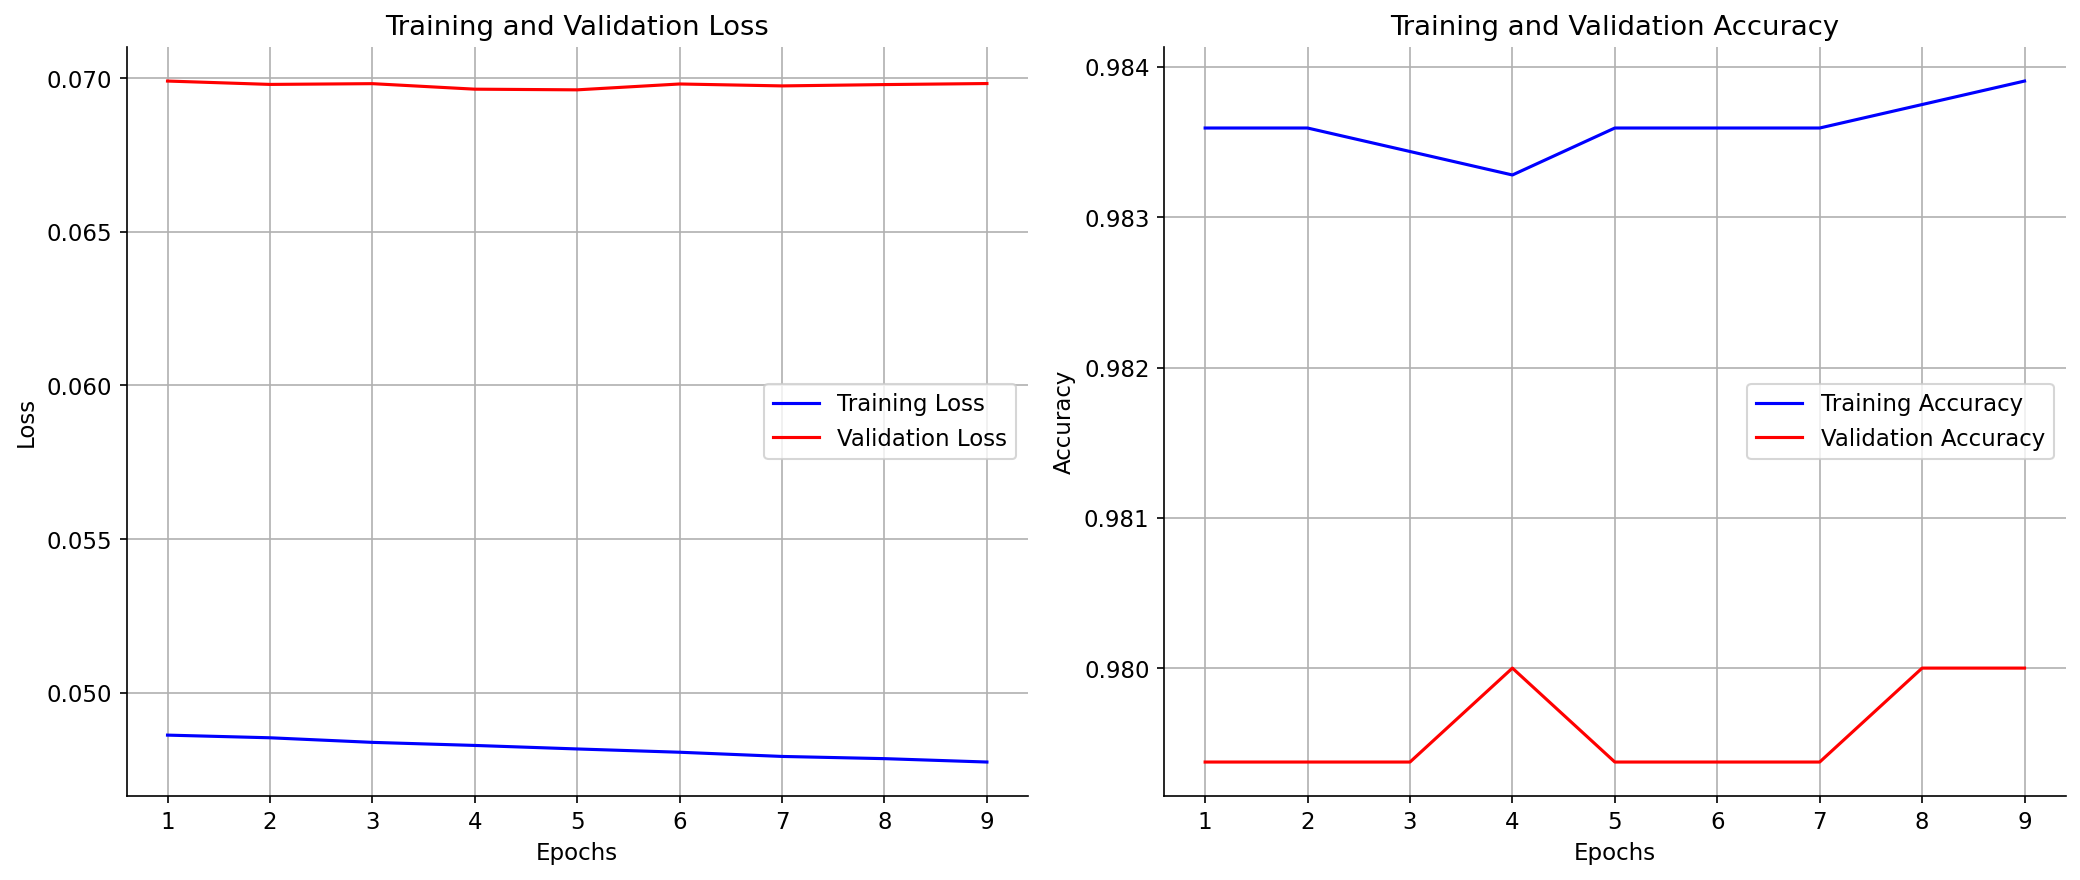


--- Báo Cáo Phân Loại (Test Set) ---
              precision    recall  f1-score   support

           0      0.984     0.995     0.989      1932
           1      0.783     0.529     0.632        68

    accuracy                          0.979      2000
   macro avg      0.883     0.762     0.810      2000
weighted avg      0.977     0.979     0.977      2000


--- Ma Trận Nhầm Lẫn (Test Set) ---
[[1922   10]
 [  32   36]]


In [88]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix

# 1. Đánh giá và in bảng giá trị loss, acc của cả dữ liệu train, valid, test
# Lấy kết quả từ history (đã chạy ở cell trước)
train_loss = history.history['loss'][-1]
train_acc = history.history['accuracy'][-1]
val_loss = history.history['val_loss'][-1]
val_acc = history.history['val_accuracy'][-1]

# Đánh giá trên tập kiểm tra
test_loss, test_acc = model.evaluate(X_te, y_te, verbose=0)

print("\n--- Bảng Tóm Tắt Hiệu Suất Mô Hình ---")
print(f"{'':<15} {'Loss':<10} {'Accuracy':<10}")
print(f"{'Training Set:':<15} {train_loss:<10.4f} {train_acc:<10.3f}")
print(f"{'Validation Set:':<15} {val_loss:<10.4f} {val_acc:<10.3f}")
print(f"{'Test Set:':<15} {test_loss:<10.4f} {test_acc:<10.3f}")

# 3. Vẽ biểu đồ loss và accuracy theo epoch
loss_values = history.history['loss']
val_loss_values = history.history['val_loss']
accuracy_values = history.history['accuracy']
val_accuracy_values = history.history['val_accuracy']
epochs = range(1, len(loss_values) + 1)

plt.figure(figsize=(14, 6))

# Biểu đồ Loss
plt.subplot(1, 2, 1) # 1 hàng, 2 cột, biểu đồ thứ nhất
plt.plot(epochs, loss_values, 'b', label='Training Loss')
plt.plot(epochs, val_loss_values, 'r', label='Validation Loss')
plt.title('Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

# Biểu đồ Accuracy
plt.subplot(1, 2, 2) # 1 hàng, 2 cột, biểu đồ thứ hai
plt.plot(epochs, accuracy_values, 'b', label='Training Accuracy')
plt.plot(epochs, val_accuracy_values, 'r', label='Validation Accuracy')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

# 2. In báo cáo phân loại và ma trận nhầm lẫn
# y_pred đã được tính toán ở cell trước az9Bikqb0qkE
# Nếu y_pred chưa có, cần tính lại: y_prob = model.predict(X_te, verbose=0); y_pred = (y_prob[:, 0] > 0.5).astype(int)

print("\n--- Báo Cáo Phân Loại (Test Set) ---")
print(classification_report(y_te, y_pred, digits=3))

print("\n--- Ma Trận Nhầm Lẫn (Test Set) ---")
print(confusion_matrix(y_te, y_pred))

## (6) Dự đoán: predict()

In [89]:
# Dự đoán đầu ra cho tập dữ liệu kiểm tra X_te. Vì đây là bài toán phân loại nhị phân với lớp đầu ra sigmoid, y_prob sẽ chứa các giá trị xác suất (từ 0 đến 1) cho lớp dương tính.
y_prob = model.predict(X_te, batch_size=256, verbose=0)
print("Kích thước y:", y_prob.shape)          # (kích thước của y_prob)
# Sử dụng np.array2string để định dạng mảng numpy với số chữ số thập phân mong muốn
print("y_prob = ", np.array2string(y_prob.flatten(), formatter={'float_kind':lambda x: "%.3f" % x}))

# Chuyển đổi giá trị xác xuất thành giá trị đầu ra
import numpy as np
# y_pred = np.argmax(y_prob, axis=1)   # lop ra Softmax
y_pred = (y_prob[:, 0] > 0.5).astype(int)  # lop ra Sigmoid
print("y_pred = ", y_pred)

Kích thước y: (2000, 1)
y_prob =  [0.235 0.000 0.015 ... 0.000 0.006 0.000]
y_pred =  [0 0 0 ... 0 0 0]


## (7) Chương trình hoàn chỉnh


# Tải dữ liệu
Da co ai4i2020.csv: 522048 byte

# Khai báo mạng


Model: "sequential_104"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_324 (Dense)               │ (None, 32)             │           288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_325 (Dense)               │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_326 (Dense)               │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 833 (3.25 KB)

 Trainable params: 833 (3.25 KB)

 Non-trainable params: 0 (0.00 B)


# Biên dịch mạng
# Huấn luyện mạng
(6400, 8) (1600, 8) (2000, 8)
Đang huấn luyện mạng ...

Kết thúc huấn luyện!
Số epoch đã chạy: 81
Training Accuracy: 0.982
Training Loss: 0.050
Validation Accuracy: 0.984
Validation Loss: 0.063
# Đánh giá mạng

--- Bảng Tóm Tắt Hiệu Suất Mô Hình ---
                Loss       Accuracy  
Training Set:   0.0503     0.982     
Validation Set: 0.0629     0.984     
Test Set:       0.0658     0.979     


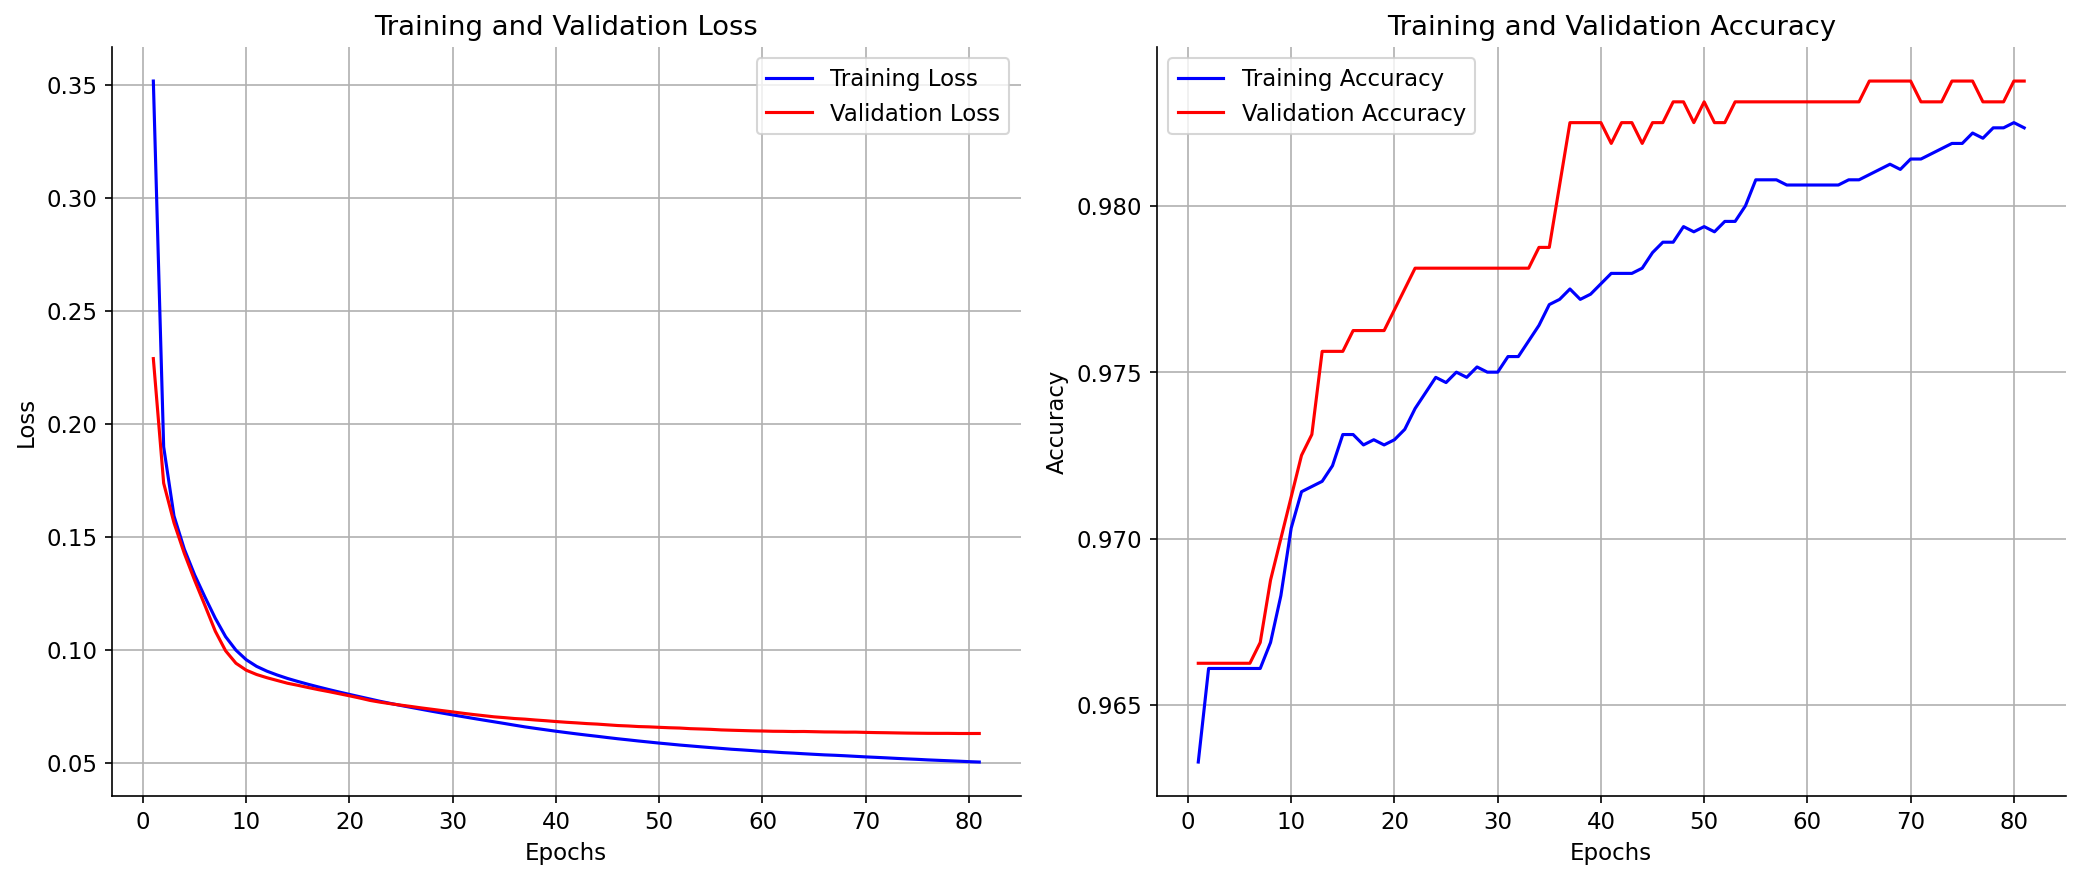


--- Báo Cáo Phân Loại (Test Set) ---
              precision    recall  f1-score   support

           0      0.984     0.994     0.989      1932
           1      0.766     0.529     0.626        68

    accuracy                          0.979      2000
   macro avg      0.875     0.762     0.808      2000
weighted avg      0.976     0.979     0.977      2000


--- Ma Trận Nhầm Lẫn (Test Set) ---
[[1921   11]
 [  32   36]]

# Dự đoán trên dữ liệu test
Kích thước y: (2000, 1)
y_prob =  [0.269 0.002 0.009 ... 0.000 0.012 0.000]
y_pred =  [0 0 0 ... 0 0 0]


In [90]:
#(*) Tải dữ liệu
# Tai bo du lieu AI4I 2020 ve thu muc lam viec cua Colab (chay mot lan).
# Neu tai khong duoc, tai tay tep ai4i2020.csv tai
# https://archive.ics.uci.edu/dataset/601 roi tai len Colab.
import os, urllib.request, zipfile
print("\n# Tải dữ liệu")
URL = ("https://archive.ics.uci.edu/static/public/601/"
       "ai4i+2020+predictive+maintenance+dataset.zip")
if not os.path.exists("ai4i2020.csv"):
    urllib.request.urlretrieve(URL, "ai4i2020.zip")
    with zipfile.ZipFile("ai4i2020.zip") as z:
        z.extract("ai4i2020.csv")
print("Da co ai4i2020.csv:", os.path.getsize("ai4i2020.csv"), "byte")

# Khai báo mạng
print("\n# Khai báo mạng")
from tensorflow import keras
# Mang 9-64-32-10 cho bai toan chan doan o lan
# Mang 8-32-16-1
model = keras.Sequential([
    keras.layers.Input(shape=(8,)),
    keras.layers.Dense(32, activation="relu"),
    keras.layers.Dense(16, activation="relu"),
    # keras.layers.Dense(1) # output hồi quy
    keras.layers.Dense(1, activation="sigmoid") # output 2 trạng thái
    # keras.layers.Dense(10, activation="softmax"),  # output 10 trang thai
])
model.summary()

# Biên dịch mạng
print("\n# Biên dịch mạng")
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

# Huấn luyện mạng
print("# Huấn luyện mạng")
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# 1. Chuan bi du lieu: 5 dai luong do + loai may (L/M/H) -> 8 cot
df = pd.read_csv("ai4i2020.csv")
DO = ["Air temperature [K]", "Process temperature [K]",
      "Rotational speed [rpm]", "Torque [Nm]", "Tool wear [min]"]
X = pd.concat([df[DO], pd.get_dummies(df["Type"], dtype=float)],
              axis=1).values
y = df["Machine failure"].values    # 0 binh thuong, 1 hong

# Chia 64 / 16 / 20 %, giu nguyen ti le mau hong o ca ba tap
X_tam, X_te, y_tam, y_te = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)
X_tr, X_val, y_tr, y_val = train_test_split(
    X_tam, y_tam, test_size=0.2, stratify=y_tam, random_state=42)

# Chuan hoa: tham so chi uoc luong tren tap huan luyen
chuan_hoa = StandardScaler().fit(X_tr)
X_tr, X_val, X_te = [chuan_hoa.transform(a)
                     for a in (X_tr, X_val, X_te)]
print(X_tr.shape, X_val.shape, X_te.shape)   # 6400/1600/2000

early_stop = keras.callbacks.EarlyStopping(
    monitor="val_loss",          # chi so theo doi
    patience=5,                  # so epoch chiu dung
    min_delta=1e-4,              # muc cai thien toi thieu
    restore_best_weights=True)   # giu bo trong so tot nhat

print("Đang huấn luyện mạng ...")
history = model.fit(
    X_tr, y_tr,
    validation_data=(X_val, y_val),  # hoac validation_split=0.2
    epochs=100,           # so luot duyet het tap huan luyen
    batch_size=128,      # so mau moi lo; 616 mau -> 5 lo/epoch
    shuffle=True,        # tron lai truoc moi epoch (mac dinh)
    verbose=0,           # 0 im lang, 1 thanh tien trinh,
                         # 2 moi epoch mot dong
    #class_weight={0: 1.0, 1: 5.0},   # khi lech lop
    callbacks=[early_stop]
)

print("\nKết thúc huấn luyện!")
num_epochs = len(history.history['loss'])
print(f"Số epoch đã chạy: {num_epochs}")
print(f"Training Accuracy: {history.history['accuracy'][-1]:.3f}")
print(f"Training Loss: {history.history['loss'][-1]:.3f}")
print(f"Validation Accuracy: {history.history['val_accuracy'][-1]:.3f}")
print(f"Validation Loss: {history.history['val_loss'][-1]:.3f}")

# Đánh giá mạng
print("# Đánh giá mạng")
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix

# 1. Đánh giá và in bảng giá trị loss, acc của cả dữ liệu train, valid, test
# Lấy kết quả từ history (đã chạy ở cell trước)
train_loss = history.history['loss'][-1]
train_acc = history.history['accuracy'][-1]
val_loss = history.history['val_loss'][-1]
val_acc = history.history['val_accuracy'][-1]

# Đánh giá trên tập kiểm tra
test_loss, test_acc = model.evaluate(X_te, y_te, verbose=0)

print("\n--- Bảng Tóm Tắt Hiệu Suất Mô Hình ---")
print(f"{'':<15} {'Loss':<10} {'Accuracy':<10}")
print(f"{'Training Set:':<15} {train_loss:<10.4f} {train_acc:<10.3f}")
print(f"{'Validation Set:':<15} {val_loss:<10.4f} {val_acc:<10.3f}")
print(f"{'Test Set:':<15} {test_loss:<10.4f} {test_acc:<10.3f}")

# 3. Vẽ biểu đồ loss và accuracy theo epoch
loss_values = history.history['loss']
val_loss_values = history.history['val_loss']
accuracy_values = history.history['accuracy']
val_accuracy_values = history.history['val_accuracy']
epochs = range(1, len(loss_values) + 1)

plt.figure(figsize=(14, 6))

# Biểu đồ Loss
plt.subplot(1, 2, 1) # 1 hàng, 2 cột, biểu đồ thứ nhất
plt.plot(epochs, loss_values, 'b', label='Training Loss')
plt.plot(epochs, val_loss_values, 'r', label='Validation Loss')
plt.title('Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

# Biểu đồ Accuracy
plt.subplot(1, 2, 2) # 1 hàng, 2 cột, biểu đồ thứ hai
plt.plot(epochs, accuracy_values, 'b', label='Training Accuracy')
plt.plot(epochs, val_accuracy_values, 'r', label='Validation Accuracy')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

# 2. In báo cáo phân loại và ma trận nhầm lẫn
# y_pred đã được tính toán ở cell trước az9Bikqb0qkE
# Nếu y_pred chưa có, cần tính lại: y_prob = model.predict(X_te, verbose=0); y_pred = (y_prob[:, 0] > 0.5).astype(int)

print("\n--- Báo Cáo Phân Loại (Test Set) ---")
print(classification_report(y_te, y_pred, digits=3))

print("\n--- Ma Trận Nhầm Lẫn (Test Set) ---")
print(confusion_matrix(y_te, y_pred))

# Dự đoán trên dữ liệu test
print("\n# Dự đoán trên dữ liệu test")
# Dự đoán đầu ra cho tập dữ liệu kiểm tra X_te. Vì đây là bài toán phân loại nhị phân với lớp đầu ra sigmoid, y_prob sẽ chứa các giá trị xác suất (từ 0 đến 1) cho lớp dương tính.
y_prob = model.predict(X_te, batch_size=256, verbose=0)
print("Kích thước y:", y_prob.shape)          # (kích thước của y_prob)
# Sử dụng np.array2string để định dạng mảng numpy với số chữ số thập phân mong muốn
print("y_prob = ", np.array2string(y_prob.flatten(), formatter={'float_kind':lambda x: "%.3f" % x}))

# Chuyển đổi giá trị xác xuất thành giá trị đầu ra
import numpy as np
# y_pred = np.argmax(y_prob, axis=1)   # lop ra Softmax
y_pred = (y_prob[:, 0] > 0.5).astype(int)  # lop ra Sigmoid
print("y_pred = ", y_pred)

## (8) Thêm trọng số lớp ra {0: 1, 1: 5}

In [91]:
# Chương trình đầy đủ như (7), chi them class_weight, moi thu khac
# giu nguyen (cung hat giong, cung mang, cung so epoch).
from sklearn.metrics import precision_recall_fscore_support

history_1, y_pred_1 = history, y_pred          # ket qua lan 1
keras.utils.set_random_seed(42)

model = keras.Sequential([
    keras.layers.Input(shape=(8,)),
    keras.layers.Dense(32, activation="relu"),
    keras.layers.Dense(16, activation="relu"),
    keras.layers.Dense(1, activation="sigmoid")])

model.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3),
              loss="binary_crossentropy", metrics=["accuracy"])

luu = keras.callbacks.ModelCheckpoint(
    "mang_tot_nhat_lan2.keras", monitor="val_loss",
    save_best_only=True)

history_2 = model.fit(X_tr, y_tr, validation_data=(X_val, y_val),
                      epochs=60, batch_size=64, verbose=0,
                      class_weight={0: 1.0, 1: 5.0}, callbacks=[luu]) # gán trọng số cho lớp 0 và 1

mang = keras.models.load_model("mang_tot_nhat_lan2.keras")
loss_2, acc_2 = mang.evaluate(X_te, y_te, verbose=0)
y_pred_2 = (mang.predict(X_te, verbose=0)[:, 0] > 0.5).astype(int)
P2, R2, F2, _ = precision_recall_fscore_support(
    y_te, y_pred_2, average="binary")

P, R, F, _ = precision_recall_fscore_support(
    y_te, y_pred, average="binary")

# In kết quả lần 1 (không trọng số)
print(f"Lan 1 (trong so lop 1:1): mat mat {loss:.4f} | "
      f"do chinh xac {acc:.3f} | do chuan xac {P:.3f} | "
      f"do phu {R:.3f} | F1 {F:.3f}")

print(confusion_matrix(y_te, y_pred))

# In kết quả lần 2
print(f"Lan 2 (trong so lop 1:5): mat mat {loss_2:.4f} | "
      f"do chinh xac {acc_2:.3f} | do chuan xac {P2:.3f} | "
      f"do phu {R2:.3f} | F1 {F2:.3f}")

print(confusion_matrix(y_te, y_pred_2))

Lan 1 (trong so lop 1:1): mat mat 0.0805 | do chinh xac 0.970 | do chuan xac 0.783 | do phu 0.529 | F1 0.632
[[1922   10]
 [  32   36]]
Lan 2 (trong so lop 1:5): mat mat 0.0805 | do chinh xac 0.970 | do chuan xac 0.538 | do phu 0.721 | F1 0.616
[[1890   42]
 [  19   49]]


# Bảng và hình vẽ

Đối chiếu số liệu của ví dụ AI4I với sách (Bảng 4.4, Bảng 4.5)

In [92]:
# Doi chieu so lieu cua vi du AI4I 2020 voi cac con so in o muc 4.4.6.
# O nay dung lai cac bien cua o (8): df, X, y, y_pred, acc, ...
import numpy as np
from sklearn.metrics import precision_recall_fscore_support

print("So mau            :", len(df), "| mau hong:", int(y.sum()),
      "(%.2f %%)" % (100 * y.mean()))
print("Loai may          :", df["Type"].value_counts().to_dict())
print("Cac dang hong     :",
      df[["TWF", "HDF", "PWF", "OSF", "RNF"]].sum().to_dict())
print("Tap huan luyen / kiem dinh / kiem tra:",
      len(X_tr), "/", len(X_val), "/", len(X_te))
print("Mau hong moi tap  :", int(y_tr.sum()), "/", int(y_val.sum()),
      "/", int(y_te.sum()))
print("So tham so        :", model.count_params())
print("Luon doan 'binh thuong' tren tap kiem tra: do chinh xac %.3f"
      % (1 - y_te.mean()))

P, R, F, _ = precision_recall_fscore_support(
    y_te, y_pred, average="binary")
print("Lan 1 (khong trong so lop): do chinh xac %.3f | "
      "do chuan xac %.3f | do phu %.3f | F1 %.3f" % (acc, P, R, F))

# Sau mau trich o Bang 4.4: ba mau dau tien va ba mau hong dau tien
COT = ["UDI", "Type"] + DO + ["Machine failure"]
mau = pd.concat([df.head(3), df[df["Machine failure"] == 1].head(3)])
print(mau[COT].to_string(index=False))

So mau            : 10000 | mau hong: 339 (3.39 %)
Loai may          : {'L': 6000, 'M': 2997, 'H': 1003}
Cac dang hong     : {'TWF': 46, 'HDF': 115, 'PWF': 95, 'OSF': 98, 'RNF': 19}
Tap huan luyen / kiem dinh / kiem tra: 6400 / 1600 / 2000
Mau hong moi tap  : 217 / 54 / 68
So tham so        : 833
Luon doan 'binh thuong' tren tap kiem tra: do chinh xac 0.966
Lan 1 (khong trong so lop): do chinh xac 0.970 | do chuan xac 0.783 | do phu 0.529 | F1 0.632
 UDI Type  Air temperature [K]  Process temperature [K]  Rotational speed [rpm]  Torque [Nm]  Tool wear [min]  Machine failure
   1    M                298.1                    308.6                    1551         42.8                0                0
   2    L                298.2                    308.7                    1408         46.3                3                0
   3    L                298.1                    308.5                    1498         49.4                5                0
  51    L                298.9        

**Hình 4.13** — dữ liệu AI4I 2020

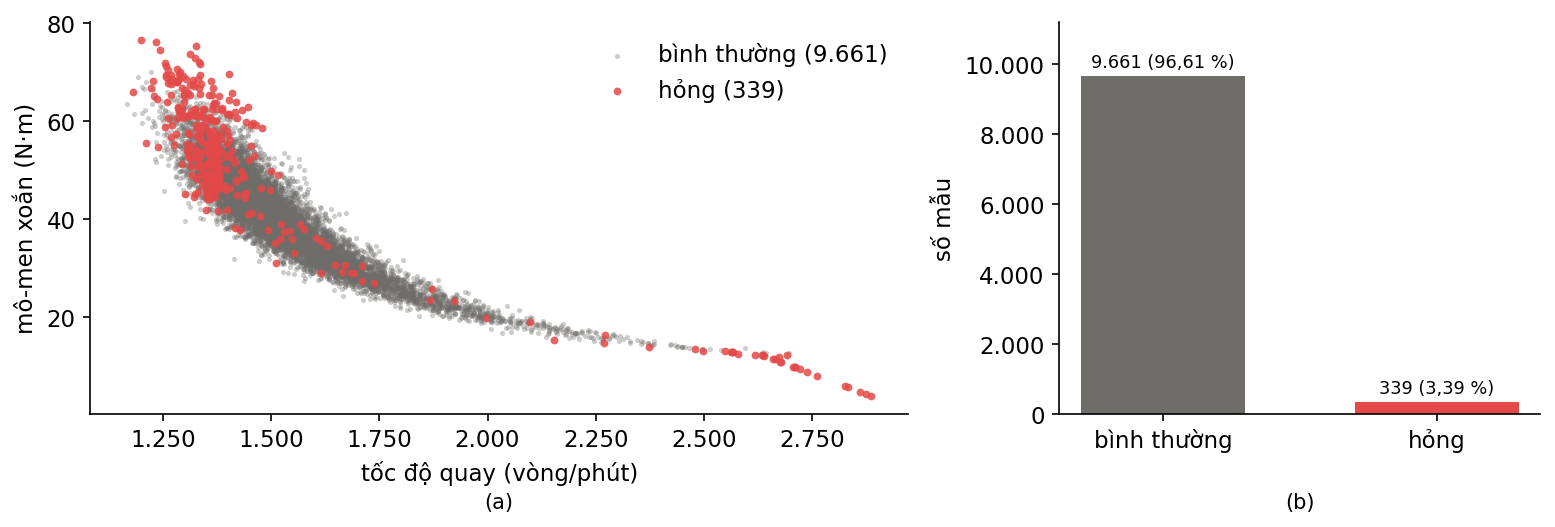

In [93]:
# Ve lai Hinh 4.13 cua giao trinh: du lieu AI4I 2020.
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

LAM, DO_, XAM = "#2A78D6", "#E34948", "#6E6D69"
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 11,
                     "figure.dpi": 150, "axes.spines.top": False,
                     "axes.spines.right": False})

def so_vn(v):
    """Dinh dang so kieu Viet Nam: 9.661 va 3,39."""
    return f"{v:,}".replace(",", ".") if isinstance(v, int) \
        else f"{v:.2f}".replace(".", ",")

bt, hong = df[df["Machine failure"] == 0], df[df["Machine failure"] == 1]
fig, (a, b) = plt.subplots(1, 2, figsize=(10.5, 4.0),
                           gridspec_kw=dict(width_ratios=[1.7, 1]))
a.scatter(bt["Rotational speed [rpm]"], bt["Torque [Nm]"], s=6,
          color=XAM, alpha=0.35, linewidths=0,
          label=f"bình thường ({so_vn(len(bt))})")
a.scatter(hong["Rotational speed [rpm]"], hong["Torque [Nm]"], s=14,
          color=DO_, alpha=0.85, linewidths=0,
          label=f"hỏng ({so_vn(len(hong))})")
a.set_xlabel("tốc độ quay (vòng/phút)"); a.set_ylabel("mô-men xoắn (N·m)")
a.legend(frameon=False, loc="upper right")

dem = [len(bt), len(hong)]
b.bar([0, 1], dem, color=[XAM, DO_], width=0.6)
for i, v in enumerate(dem):
    b.text(i, v + 250, f"{so_vn(v)} ({so_vn(100 * v / sum(dem))} %)",
           ha="center", fontsize=8.5)
b.set_xticks([0, 1]); b.set_xticklabels(["bình thường", "hỏng"])
b.set_ylim(0, 11200); b.set_ylabel("số mẫu")
for ax, nh in zip((a, b), "ab"):
    ax.text(0.5, -0.24, f"({nh})", transform=ax.transAxes,
            ha="center", fontsize=10)
dinh = FuncFormatter(lambda v, _: f"{int(round(v)):,}".replace(",", "."))
a.xaxis.set_major_formatter(dinh); b.yaxis.set_major_formatter(dinh)
plt.tight_layout(rect=(0, 0.06, 1, 1))
plt.show()

**Hình 4.14** — đường mất mát và ma trận nhầm lẫn của hai lần chạy

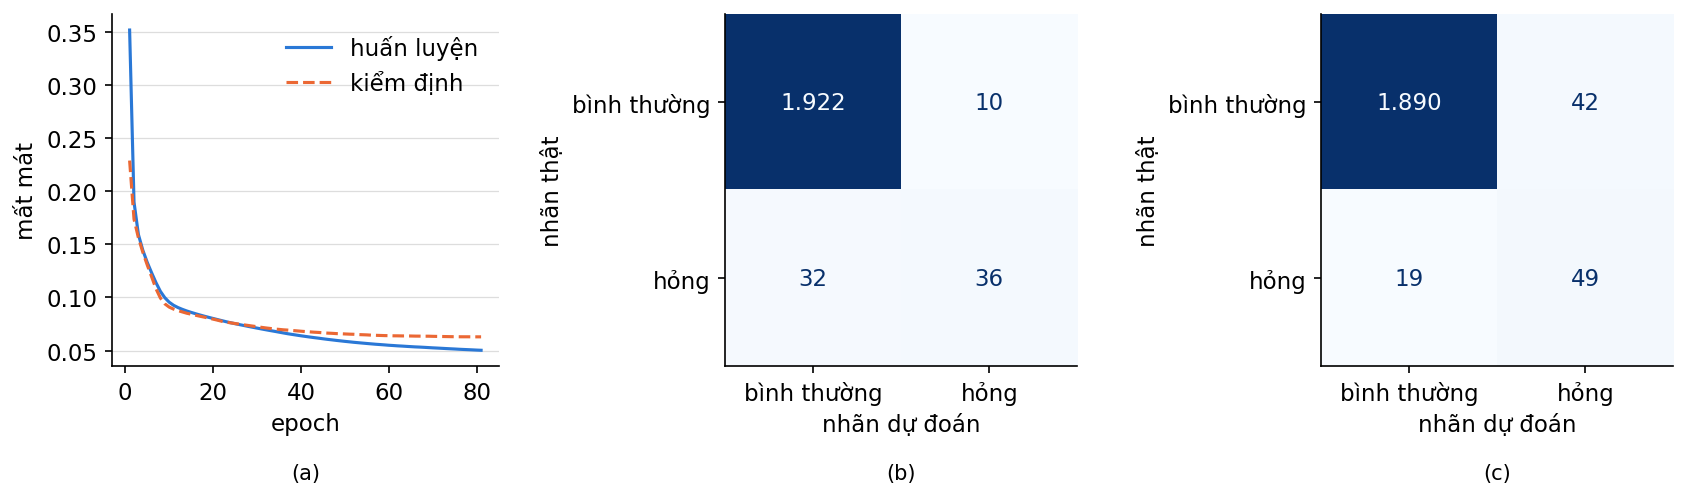

In [94]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

LAM, CAM = "#2A78D6", "#EB6834"
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 11,
                     "figure.dpi": 150, "axes.spines.top": False,
                     "axes.spines.right": False})

fig, (t1, t2, t3) = plt.subplots(1, 3, figsize=(11.5, 3.9))
ep = np.arange(1, len(history_1.history["loss"]) + 1)
t1.plot(ep, history_1.history["loss"], color=LAM, label="huấn luyện")
t1.plot(ep, history_1.history["val_loss"], "--", color=CAM,
        label="kiểm định")
t1.set_xlabel("epoch"); t1.set_ylabel("mất mát")
t1.legend(frameon=False, loc="upper right")
t1.set_axisbelow(True); t1.grid(axis="y", color="#DDDDDD", lw=0.6)

for ax, dd in ((t2, y_pred_1), (t3, y_pred_2)):
    hien = ConfusionMatrixDisplay(confusion_matrix(y_te, dd),
                                  display_labels=["bình thường", "hỏng"]
                                  ).plot(ax=ax, cmap="Blues",
                                         colorbar=False, values_format="d")
    for t in hien.text_.ravel():          # 1924 -> 1.924
        t.set_text(f"{int(t.get_text()):,}".replace(",", "."))
    ax.set_xlabel("nhãn dự đoán"); ax.set_ylabel("nhãn thật")
    ax.grid(False)

for ax, nh in zip((t1, t2, t3), "abc"):
    ax.text(0.5, -0.32, f"({nh})", transform=ax.transAxes,
            ha="center", fontsize=10)
plt.tight_layout(rect=(0, 0.06, 1, 1))
plt.show()

# Lưu và nạp lại mô hình

##(1) Lưu và nạp lại cả mô hình

In [95]:
# Sau khi huan luyen xong: ghi ca mo hinh vao MOT tep
model.save("mang_cuoi.keras")

# Ve sau (co the o phien lam viec khac): nap lai de dung
mang = keras.models.load_model("mang_cuoi.keras")
y_prob = mang.predict(X_te, verbose=0)  # dung ngay

## (2) Chỉ lưu trọng số

In [97]:
# Chi luu trong so (ten tep ket thuc bang .weights.h5)
model.save_weights("mang_cuoi.weights.h5")

# Nap lai: PHAI dung lai dung kien truc nhu luc huan luyen
mang = keras.Sequential([
    keras.layers.Input(shape=(8,)),
    keras.layers.Dense(32, activation="relu"),
    keras.layers.Dense(16, activation="relu"),
    keras.layers.Dense(1, activation="sigmoid")])
mang.load_weights("mang_cuoi.weights.h5")

## (3) Lưu trạng thái tốt nhất bằng ModelCheckpoint

In [98]:
# Callback ghi tep NGAY TRONG LUC huan luyen
luu_tot_nhat = keras.callbacks.ModelCheckpoint(
    "mang_tot_nhat.keras",
    monitor="val_loss",       # chi so theo doi
    save_best_only=True,      # chi ghi khi co cai thien
    save_weights_only=False)  # False: ghi ca kien truc

model.fit(X_tr, y_tr, validation_data=(X_val, y_val),
          epochs=100, callbacks=[early_stop, luu_tot_nhat])

# Nap lai trang thai tot nhat, khong phai cua epoch cuoi
mang = keras.models.load_model("mang_tot_nhat.keras")

Epoch 1/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9816 - loss: 0.0498 - val_accuracy: 0.9800 - val_loss: 0.0670
Epoch 2/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9825 - loss: 0.0485 - val_accuracy: 0.9812 - val_loss: 0.0674
Epoch 3/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9830 - loss: 0.0482 - val_accuracy: 0.9800 - val_loss: 0.0676
Epoch 4/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9834 - loss: 0.0480 - val_accuracy: 0.9787 - val_loss: 0.0677
Epoch 5/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9836 - loss: 0.0478 - val_accuracy: 0.9781 - val_loss: 0.0679


## (4) Lưu riêng bộ chuẩn hoá bằng joblib

In [101]:
import joblib

# Luc huan luyen: luu bo chuan hoa da fit tren tap huan luyen
joblib.dump(chuan_hoa, "chuan_hoa.pkl")

# Luc su dung: nap CA HAI, chuan hoa bang bo cu roi moi du doan
chuan_hoa = joblib.load("chuan_hoa.pkl")
mang = keras.models.load_model("mang_cuoi.keras")
# Define X_moi as new, unstandardized input data
X_moi = X[:5] # Using first 5 rows of original unscaled data as example
X_moi_chuan = chuan_hoa.transform(X_moi)   # KHONG fit lai
y_prob = mang.predict(X_moi_chuan, verbose=0)